In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [88]:
df = pd.read_csv(r"C:\Users\HP\Downloads\Large_Sales_Dataset")

In [114]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Order_Status
0,ORD000001,2023-12-10,CUST01516,Customer_02854,Male,18.0,Durgapur,West Bengal,East,Beauty,Perfume,5,2242.61,0.1,10091.75,827.47,Debit Card,Delivered
1,ORD000002,2024-11-30,CUST00976,Customer_01807,Female,29.0,Karimnagar,Telangana,South,Home Appliances,Electric Kettle,3,1840.20,0.0,5520.60,359.25,Credit Card,Delivered
2,ORD000003,2025-02-15,CUST02613,Customer_02946,Male,28.0,Delhi,Delhi,North,Sports,Tennis Racket,2,4934.91,0.1,8882.84,2213.49,Net Banking,Delivered
3,ORD000004,2024-12-03,CUST02450,Customer_02778,Female,53.0,Hubballi,Karnataka,South,Home Appliances,Vacuum Cleaner,3,7708.46,0.2,18500.30,2163.27,UPI,Delivered
4,ORD000005,2023-08-05,CUST00764,Customer_02236,Male,32.0,Mysuru,Karnataka,South,Furniture,Sofa,3,30362.50,0.0,91087.50,9392.60,UPI,Delivered


In [90]:
df.tail()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_Category,Product,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Order_Status
10010,ORD002751,2024-10-05,CUST02869,Customer_00058,Female,22.0,Hubballi,Karnataka,South,Beauty,Shampoo,3,434.92,0.05,1239.52,332.21,UPI,Delivered
10011,ORD007488,2025-07-30,CUST01530,Customer_02475,Female,39.0,Karimnagar,Telangana,South,Beauty,Perfume,6,1995.53,0.05,11374.52,1723.42,Cash,Delivered
10012,ORD005273,2024-09-22,CUST00520,Customer_02899,Male,20.0,Kakinada,Andhra Pradesh,South,Beauty,Perfume,3,2176.41,0.05,6202.77,1506.45,Credit Card,Cancelled
10013,ORD005654,2024-08-19,CUST02169,Customer_02930,Female,24.0,Kakinada,Andhra Pradesh,South,Sports,Running Shoes,4,2910.62,0.10,10478.23,2600.47,UPI,Delivered
10014,ORD004000,2023-02-01,CUST00001,Customer_00706,Female,30.0,Ahmedabad,Gujarat,West,Furniture,Office Chair,4,6992.38,0.00,27969.52,4995.31,Debit Card,Delivered


In [91]:
df.shape

(10015, 18)

In [92]:
## Questions for EDA

#1. How large is the sales dataset?
#2. What types of variables are present?
#3. Are there missing values or duplicate records?
#4. Which product categories generate the highest sales?
#5. Which regions generate the highest sales?
#6. Which products have the highest sales?
#7. How are sales distributed?
#8. Is there a relationship between quantity and sales?
#9. Is there a relationship between unit price and sales?
#10. Which payment method is most frequently used?
#11. What is the order-status distribution?
#12. Are there unusual or extreme values in the dataset?
#13. How do sales change over time?
#14. Is there a relationship between sales and profit?
#15. What data-quality problems should be addressed before further analysis?

In [93]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Gender',
       'Age', 'City', 'State', 'Region', 'Product_Category', 'Product',
       'Quantity', 'Unit_Price', 'Discount', 'Sales', 'Profit', 'Payment_Mode',
       'Order_Status'],
      dtype='str')

In [94]:
df.info

<bound method DataFrame.info of         Order_ID  Order_Date Customer_ID   Customer_Name  Gender   Age  \
0      ORD000001  2023-12-10   CUST01516  Customer_02854    Male  18.0   
1      ORD000002  2024-11-30   CUST00976  Customer_01807  Female  29.0   
2      ORD000003  2025-02-15   CUST02613  Customer_02946    Male  28.0   
3      ORD000004  2024-12-03   CUST02450  Customer_02778  Female  53.0   
4      ORD000005  2023-08-05   CUST00764  Customer_02236    Male  32.0   
...          ...         ...         ...             ...     ...   ...   
10010  ORD002751  2024-10-05   CUST02869  Customer_00058  Female  22.0   
10011  ORD007488  2025-07-30   CUST01530  Customer_02475  Female  39.0   
10012  ORD005273  2024-09-22   CUST00520  Customer_02899    Male  20.0   
10013  ORD005654  2024-08-19   CUST02169  Customer_02930  Female  24.0   
10014  ORD004000  2023-02-01   CUST00001  Customer_00706  Female  30.0   

             City           State Region Product_Category          Product  \
0

In [95]:
df.dtypes

Order_ID                str
Order_Date              str
Customer_ID             str
Customer_Name           str
Gender                  str
Age                 float64
City                    str
State                   str
Region                  str
Product_Category        str
Product                 str
Quantity              int64
Unit_Price          float64
Discount            float64
Sales               float64
Profit              float64
Payment_Mode            str
Order_Status            str
dtype: object

In [96]:
df["Order_Date"]=pd.to_datetime(df["Order_Date"])

In [97]:
print(df["Order_Date"].dtype)

datetime64[us]


In [98]:
df.isnull().sum()

Order_ID             0
Order_Date           0
Customer_ID          0
Customer_Name        0
Gender               0
Age                 80
City                60
State                0
Region               0
Product_Category     0
Product              0
Quantity             0
Unit_Price           0
Discount             0
Sales                0
Profit               0
Payment_Mode        40
Order_Status         0
dtype: int64

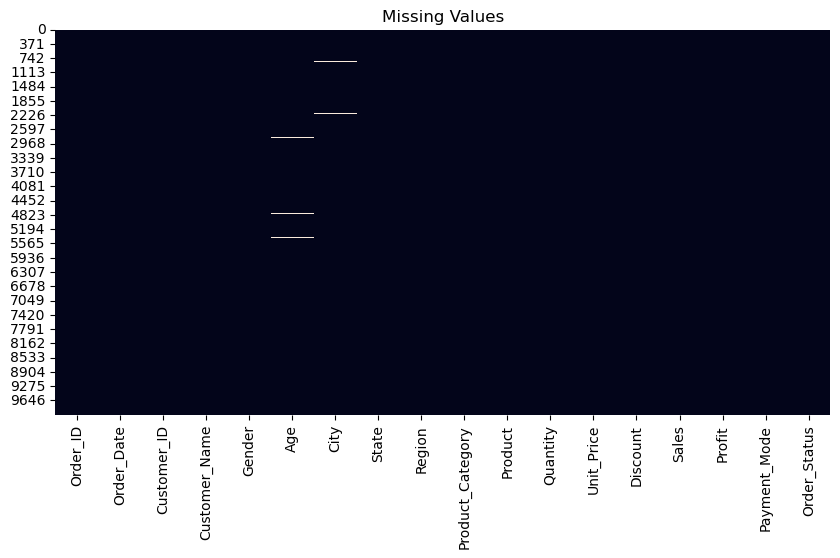

In [99]:
plt.figure(figsize=(10,5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show() 

In [100]:
missing_percentage=(df.isnull().sum() / len(df))*100
missing_percentage[missing_percentage > 0]

Age             0.798802
City            0.599101
Payment_Mode    0.399401
dtype: float64

In [101]:
print(df.duplicated().sum())

15


In [102]:
df.describe()

,Order_Date,Age,Quantity,Unit_Price,Discount,Sales,Profit
count,10015,9935.000000,10015.000000,10015.000000,10015.000000,1.001500e+04,10015.000000
mean,2024-06-29 07:15:48.617074,33.671062,3.323814,8115.264434,0.100709,2.413670e+04,4014.266114
min,2023-01-01 00:00:00,18.000000,1.000000,405.590000,0.000000,3.327400e+02,27.160000
25%,2023-09-30 00:00:00,27.000000,2.000000,1808.970000,0.050000,3.599540e+03,549.220000
50%,2024-07-04 00:00:00,33.000000,3.000000,3334.610000,0.100000,8.919900e+03,1451.120000
75%,2025-03-24 00:00:00,40.000000,4.000000,9103.055000,0.150000,2.377082e+04,3892.640000
max,2025-12-31 00:00:00,70.000000,100.000000,60478.730000,0.250000,5.026055e+06,105686.970000
std,NaN,9.488313,3.306566,11333.661701,0.072389,6.472856e+04,7560.094320


In [103]:
df.describe(include="object")

C:\Users\HP\AppData\Local\Temp\ipykernel_19164\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Order_ID,Customer_ID,Customer_Name,Gender,City,State,Region,Product_Category,Product,Payment_Mode,Order_Status
count,10015,10015,10015,10015,9955,10015,10015,10015,10015,9975,10015
unique,10000,2906,2895,3,28,8,4,6,30,5,3
top,ORD000440,CUST00092,Customer_00011,Female,Delhi,Maharashtra,South,Clothing,Perfume,UPI,Delivered
freq,2,12,11,4884,664,1301,4941,1692,363,3432,9247


In [104]:
df.nunique()

Order_ID            10000
Order_Date           1096
Customer_ID          2906
Customer_Name        2895
Gender                  3
Age                    50
City                   28
State                   8
Region                  4
Product_Category        6
Product                30
Quantity                9
Unit_Price           9929
Discount                6
Sales                9980
Profit               9876
Payment_Mode            5
Order_Status            3
dtype: int64

In [105]:
df["Gender"].value_counts()

Gender
Female    4884
Male      4869
Other      262
Name: count, dtype: int64

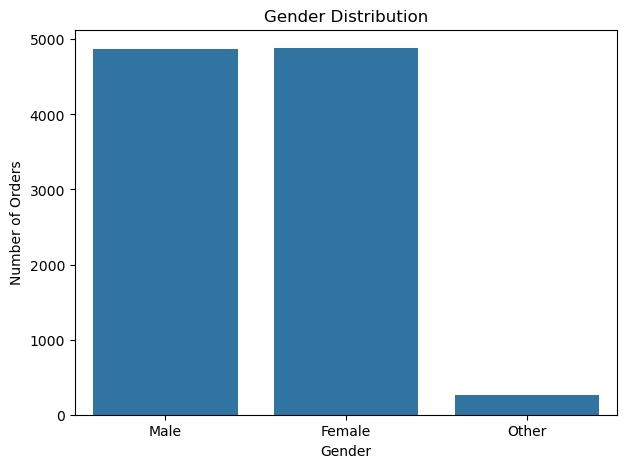

In [106]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="Gender")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Orders")
plt.show()

In [107]:
df["Region"].value_counts()

Region
South    4941
West     2529
North    1274
East     1271
Name: count, dtype: int64

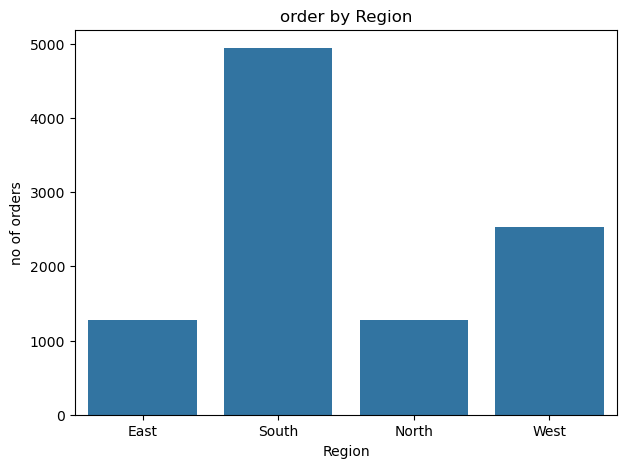

In [22]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x="Region")
plt.title("order by Region")
plt.xlabel("Region")
plt.ylabel("no of orders")
plt.show()

In [23]:
df["Product_Category"].value_counts()

Product_Category
Clothing           1692
Home Appliances    1681
Beauty             1670
Furniture          1659
Electronics        1659
Sports             1654
Name: count, dtype: int64

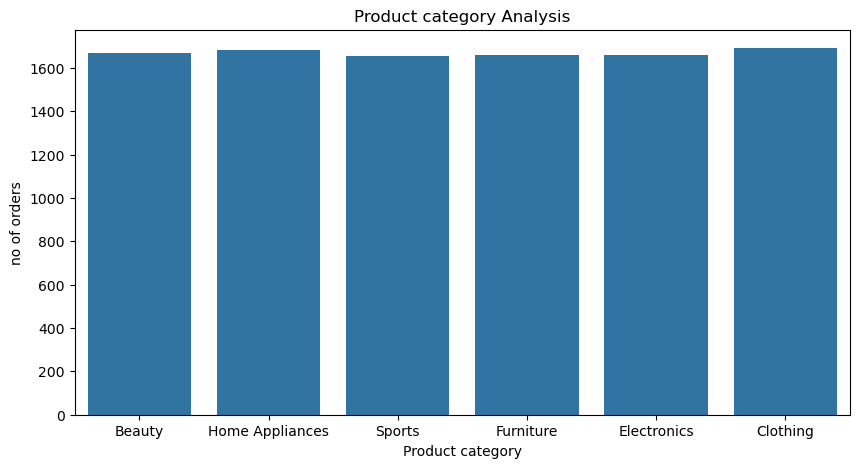

In [24]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="Product_Category")
plt.title("Product category Analysis")
plt.xlabel("Product category")
plt.ylabel("no of orders")
plt.show()

In [25]:
category_sales = df.groupby("Product_Category")["Sales"].sum().sort_values(ascending=False)

category_sales

Product_Category
Electronics        1.036371e+08
Furniture          7.287191e+07
Home Appliances    3.397058e+07
Sports             1.398800e+07
Clothing           1.119182e+07
Beauty             6.069678e+06
Name: Sales, dtype: float64

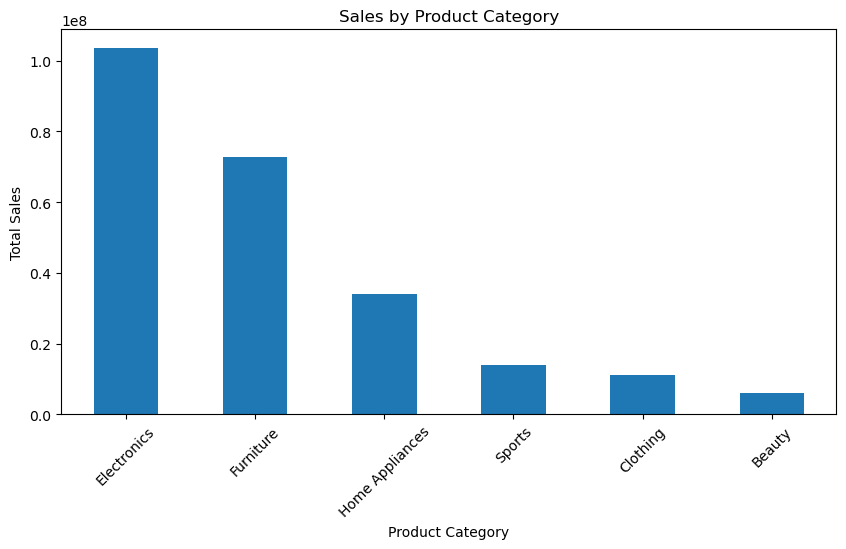

In [26]:
plt.figure(figsize=(10,5))
category_sales.plot(kind="bar")
plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [27]:
category_profit = df.groupby("Product_Category")["Profit"].sum().sort_values(ascending=False)

category_profit

Product_Category
Electronics        17253902.57
Furniture          12159800.55
Home Appliances     5655395.62
Sports              2269570.17
Clothing            1835103.26
Beauty              1029102.96
Name: Profit, dtype: float64

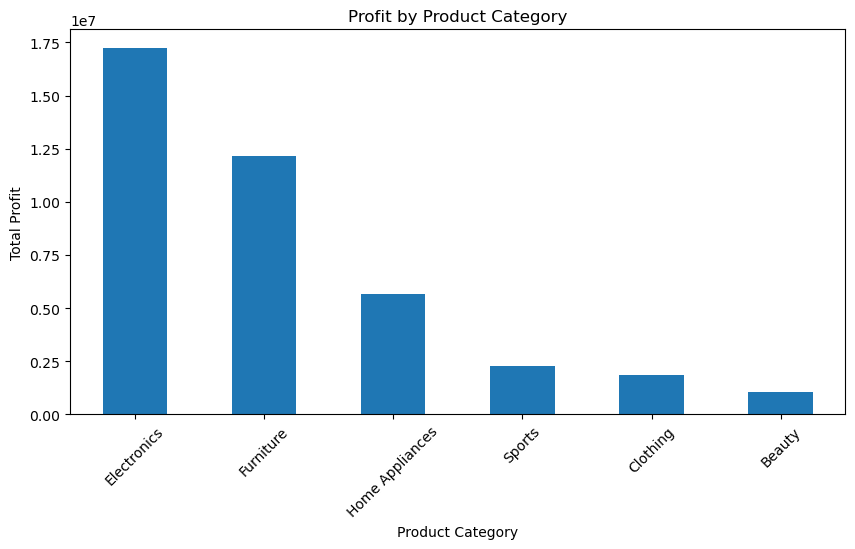

In [28]:
plt.figure(figsize=(10,5))
category_profit.plot(kind="bar")
plt.title("Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=45)
plt.show()

In [29]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

region_sales

Region
South    1.186476e+08
West     5.660323e+07
North    3.535533e+07
East     3.112292e+07
Name: Sales, dtype: float64

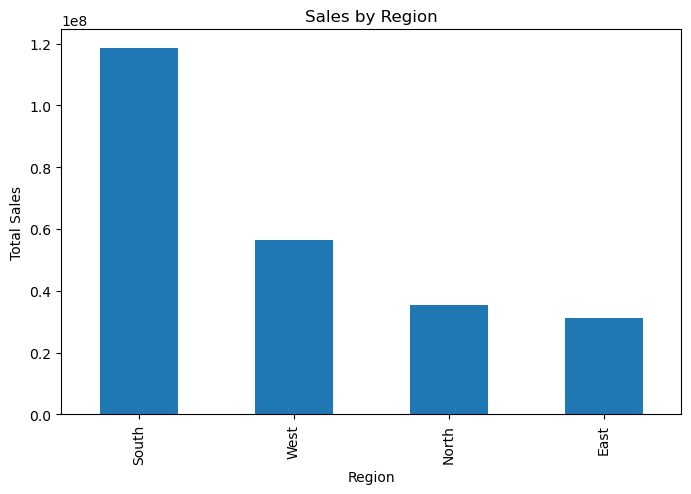

In [30]:
plt.figure(figsize=(8,5))
region_sales.plot(kind="bar")
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.show()

In [31]:
state_sales = df.groupby("State")["Sales"].sum().sort_values(ascending=False)

state_sales

State
Delhi             35355334.93
Andhra Pradesh    31477132.51
West Bengal       31122917.92
Karnataka         30959843.26
Maharashtra       29412032.69
Tamil Nadu        28725835.75
Telangana         27484799.93
Gujarat           27191193.78
Name: Sales, dtype: float64

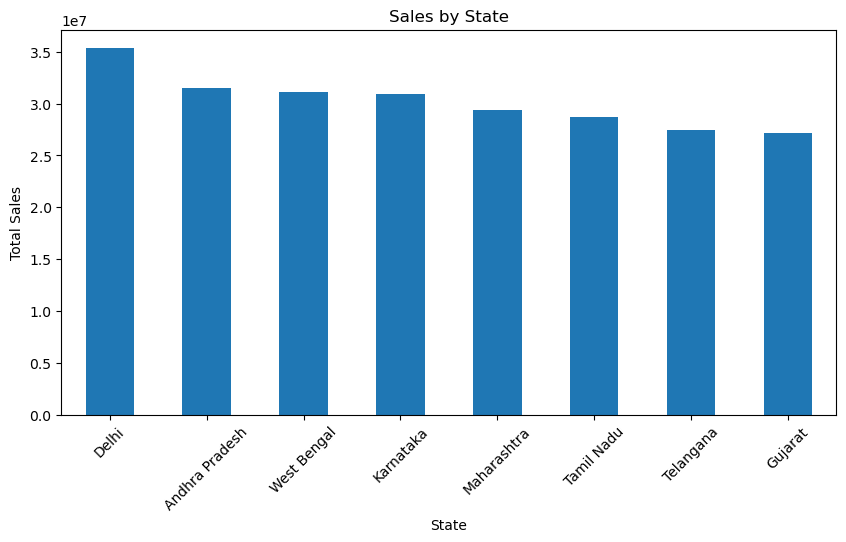

In [32]:
plt.figure(figsize=(10,5))
state_sales.plot(kind="bar")
plt.title("Sales by State")
plt.xlabel("State")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [33]:
top_products = df.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(10)

top_products

Product
Laptop            53347642.78
Smartphone        27107654.41
Sofa              26858572.40
Dining Table      21132384.27
Tablet            16178125.66
Air Cooler        11715410.39
Desk              11573419.70
Microwave          8826354.50
Vacuum Cleaner     8029578.83
Office Chair       6991047.29
Name: Sales, dtype: float64

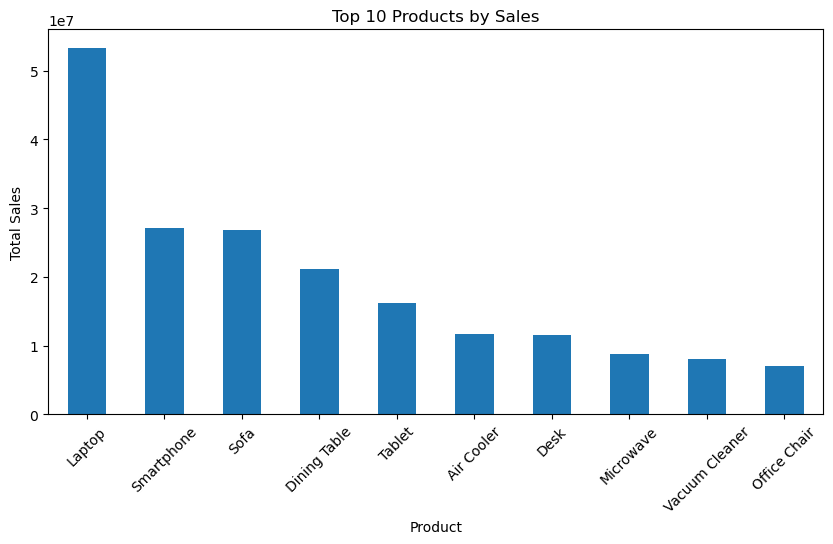

In [34]:
plt.figure(figsize=(10,5))
top_products.plot(kind="bar")
plt.title("Top 10 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [35]:
df["Payment_Mode"].value_counts()

Payment_Mode
UPI            3432
Credit Card    2396
Debit Card     2017
Cash           1189
Net Banking     941
Name: count, dtype: int64

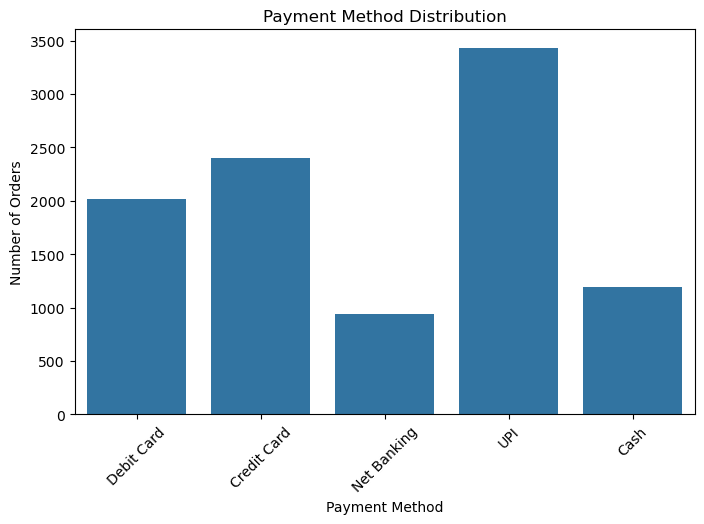

In [36]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Payment_Mode")
plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

In [37]:
df["Order_Status"].value_counts()

Order_Status
Delivered    9247
Cancelled     488
Returned      280
Name: count, dtype: int64

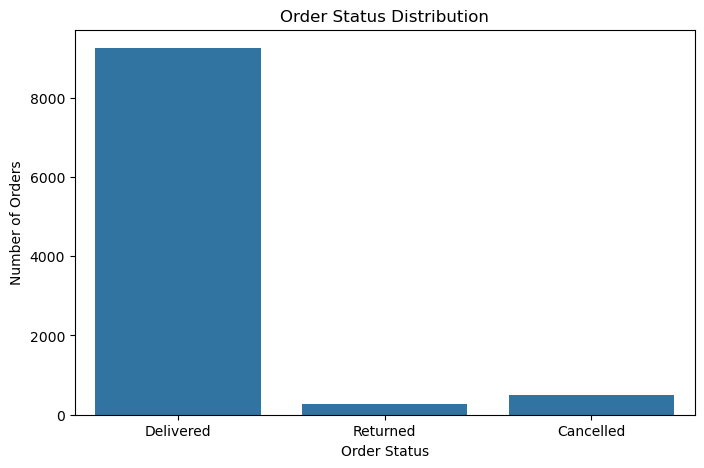

In [38]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Order_Status")
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.show()

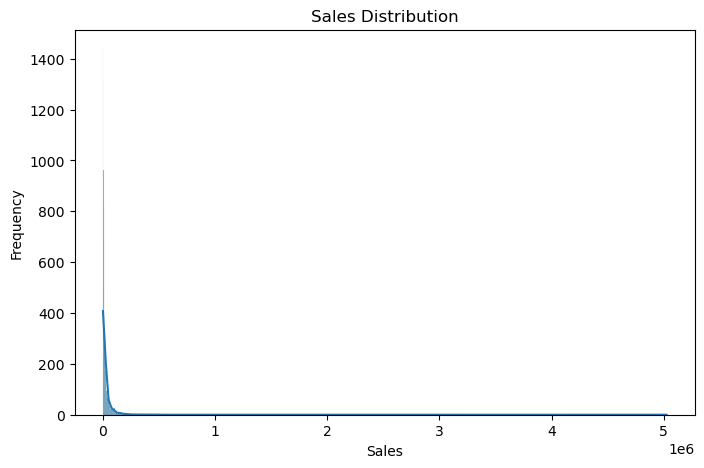

In [39]:
plt.figure(figsize=(8,5))
sns.histplot(df["Sales"], kde=True)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

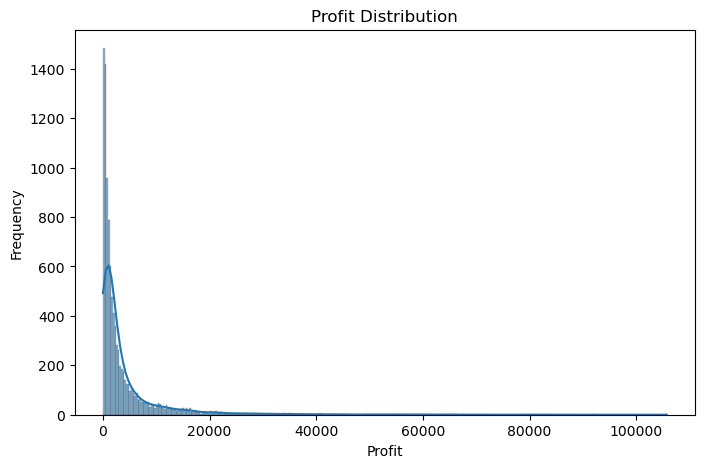

In [40]:
plt.figure(figsize=(8,5))
sns.histplot(df["Profit"], kde=True)
plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

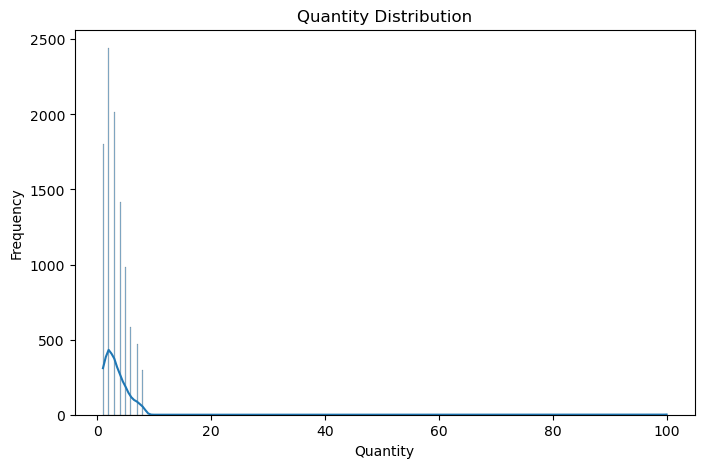

In [41]:
plt.figure(figsize=(8,5))
sns.histplot(df["Quantity"], kde=True)
plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.show()

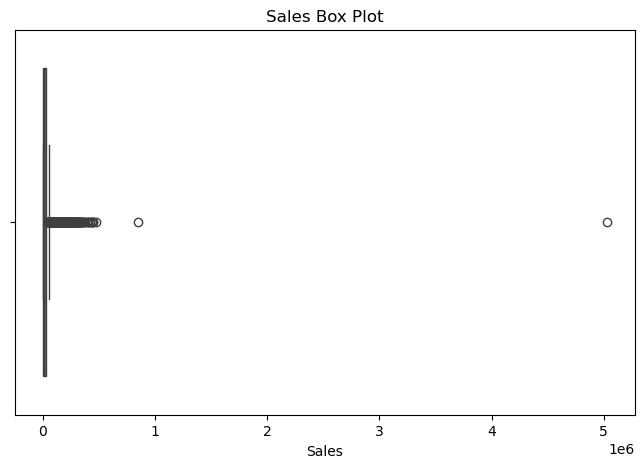

In [42]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["Sales"])
plt.title("Sales Box Plot")
plt.xlabel("Sales")
plt.show()

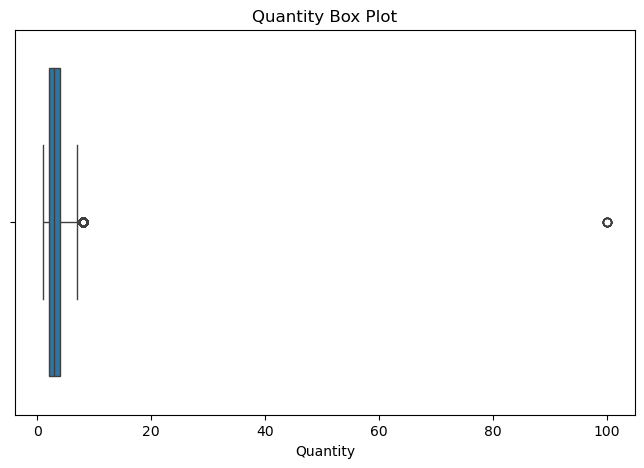

In [43]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df["Quantity"])
plt.title("Quantity Box Plot")
plt.xlabel("Quantity")
plt.show()

In [85]:
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Sales"] < lower_limit) |
    (df["Sales"] > upper_limit)
]

print("Number of Sales Outliers:", len(outliers))

Number of Sales Outliers: 1152


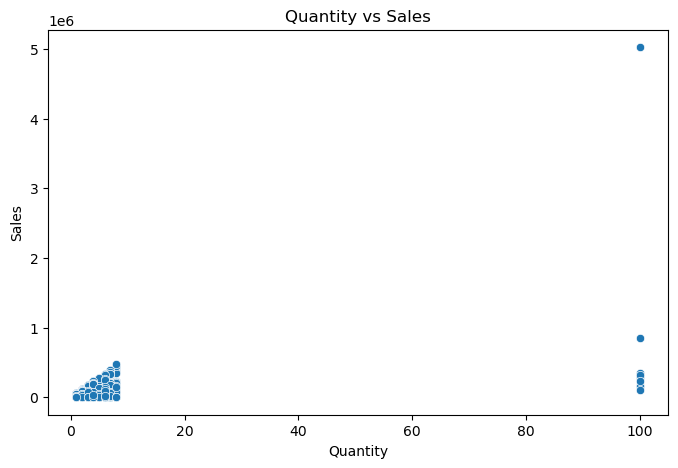

In [45]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Quantity", y="Sales")
plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.show()

In [46]:
df[["Quantity", "Sales"]].corr()

,Quantity,Sales
Quantity,1.000000,0.433556
Sales,0.433556,1.000000


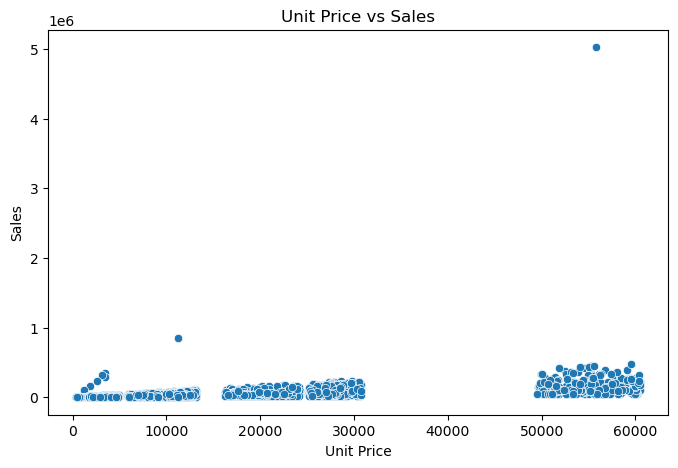

In [47]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Unit_Price", y="Sales")
plt.title("Unit Price vs Sales")
plt.xlabel("Unit Price")
plt.ylabel("Sales")
plt.show()

In [48]:
df[["Unit_Price", "Sales"]].corr()

,Unit_Price,Sales
Unit_Price,1.000000,0.530949
Sales,0.530949,1.000000


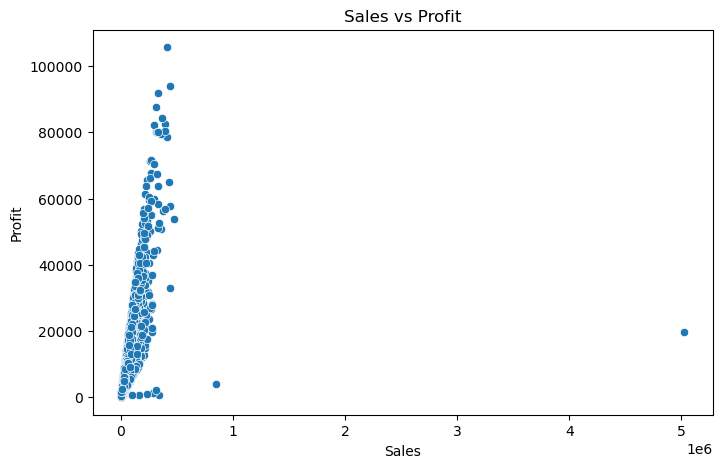

In [49]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Sales", y="Profit")
plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

In [50]:
df[["Sales", "Profit"]].corr()

,Sales,Profit
Sales,1.000000,0.584285
Profit,0.584285,1.000000


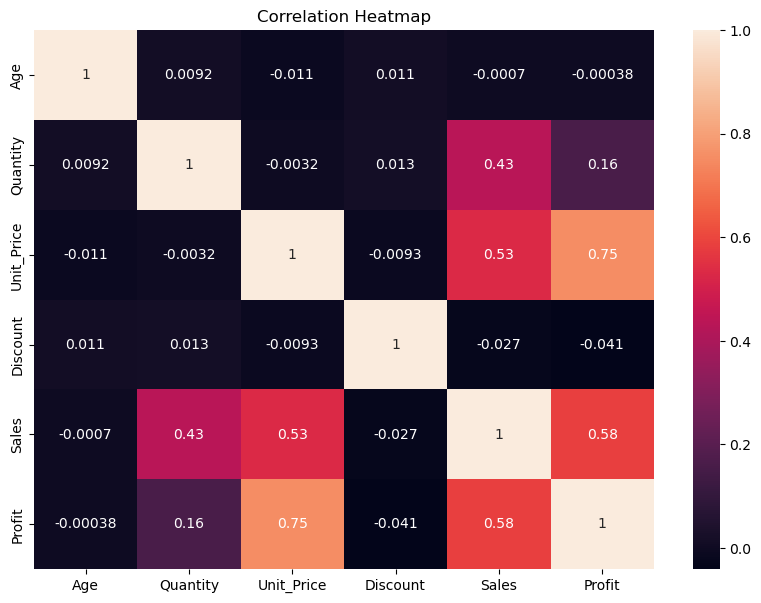

In [51]:
numeric_columns = [
    "Age",
    "Quantity",
    "Unit_Price",
    "Discount",
    "Sales",
    "Profit"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10,7))
sns.heatmap(correlation, annot=True)
plt.title("Correlation Heatmap")
plt.show()

In [52]:
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month

In [53]:
yearly_sales = df.groupby("Year")["Sales"].sum()

yearly_sales

Year
2023    76829664.58
2024    79120057.29
2025    85779368.90
Name: Sales, dtype: float64

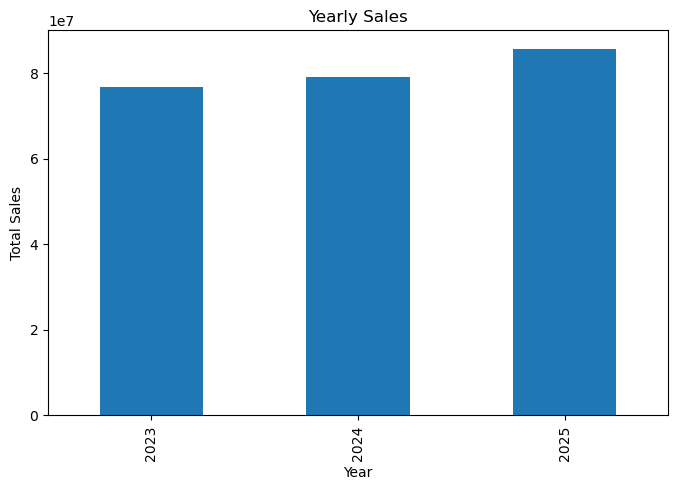

In [54]:
plt.figure(figsize=(8,5))
yearly_sales.plot(kind="bar")
plt.title("Yearly Sales")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.show()

In [55]:
df["Year_Month"] = df["Order_Date"].dt.to_period("M")

In [56]:
monthly_sales = df.groupby("Year_Month")["Sales"].sum()

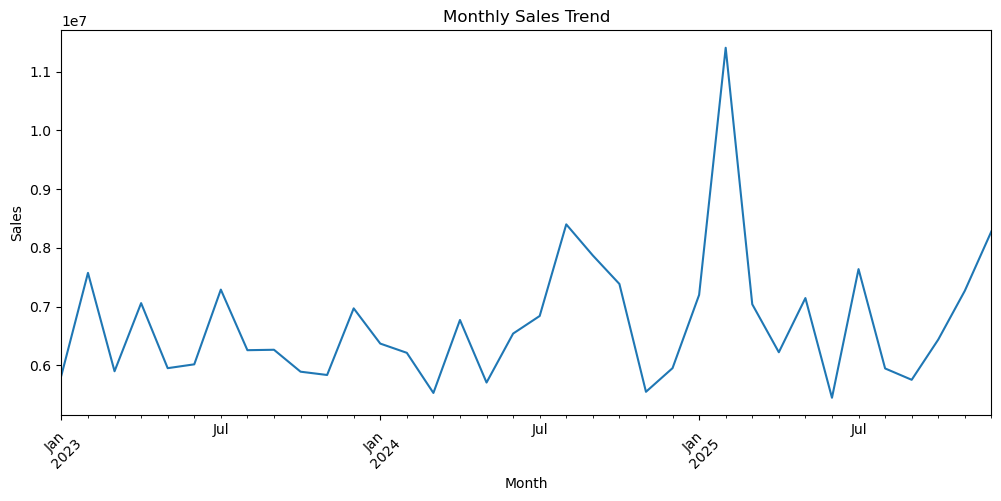

In [57]:
plt.figure(figsize=(12,5))
monthly_sales.plot()
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.show()

In [58]:
gender_sales = df.groupby("Gender")["Sales"].mean()

gender_sales

Gender
Female    24301.533841
Male      23932.944001
Other     24850.744847
Name: Sales, dtype: float64

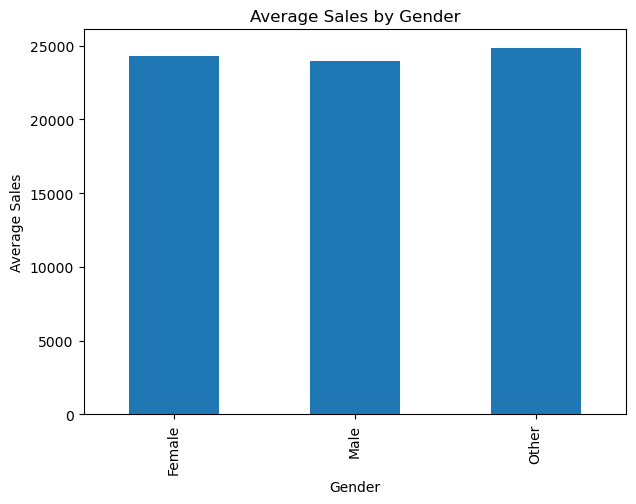

In [59]:
plt.figure(figsize=(7,5))
gender_sales.plot(kind="bar")
plt.title("Average Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Sales")
plt.show()

In [60]:
status_sales = df.groupby("Order_Status")["Sales"].sum()

status_sales

Order_Status
Cancelled    1.085807e+07
Delivered    2.238404e+08
Returned     7.030578e+06
Name: Sales, dtype: float64

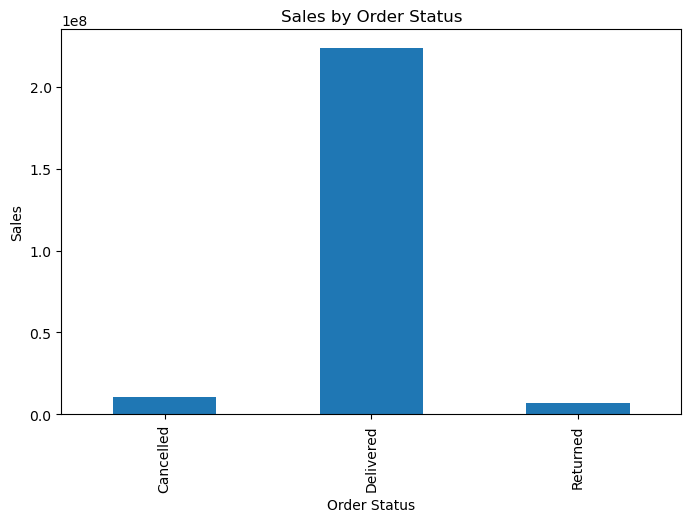

In [61]:
plt.figure(figsize=(8,5))
status_sales.plot(kind="bar")
plt.title("Sales by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Sales")
plt.show()

In [62]:
discount_category = df.groupby("Product_Category")["Discount"].mean()

discount_category

Product_Category
Beauty             0.101557
Clothing           0.100739
Electronics        0.099458
Furniture          0.100362
Home Appliances    0.102380
Sports             0.099728
Name: Discount, dtype: float64

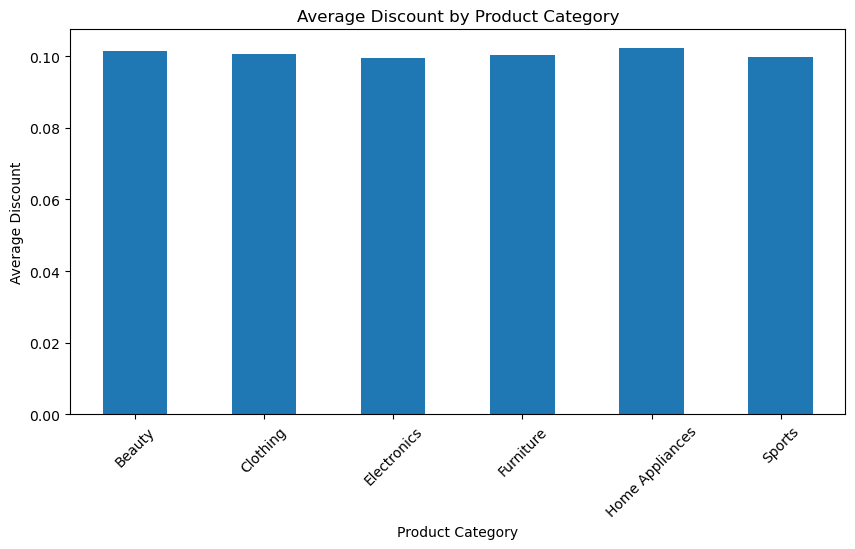

In [63]:
plt.figure(figsize=(10,5))
discount_category.plot(kind="bar")
plt.title("Average Discount by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Discount")
plt.xticks(rotation=45)
plt.show()

In [64]:
correlation = df["Quantity"].corr(df["Sales"])

print("Correlation between Quantity and Sales:", correlation)

Correlation between Quantity and Sales: 0.4335559558607344


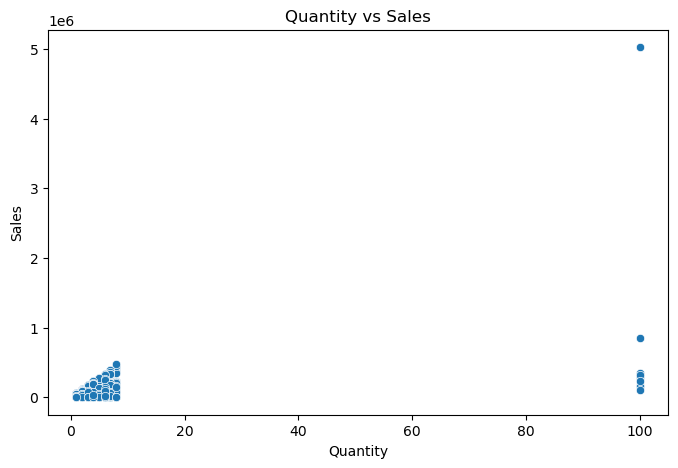

In [65]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Quantity", y="Sales")
plt.title("Quantity vs Sales")
plt.xlabel("Quantity")
plt.ylabel("Sales")
plt.show()

In [66]:
### Hypothesis Result

#The analysis shows a positive relationship between Quantity and Sales.
#The correlation coefficient is approximately 0.43.

#The scatter plot also provides visual evidence of this positive relationship.
#However, correlation does not establish causation.

In [67]:
df["Age"].describe()

count    9935.000000
mean       33.671062
std         9.488313
min        18.000000
25%        27.000000
50%        33.000000
75%        40.000000
max        70.000000
Name: Age, dtype: float64

In [68]:
df[(df["Age"] < 18) | (df["Age"] > 100)]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_Category,...,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Order_Status,Year,Month,Year_Month


In [69]:
df[df["Quantity"] > 20]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_Category,...,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Order_Status,Year,Month,Year_Month
869,ORD000870,2024-10-29,CUST00690,Customer_01882,Male,32.0,Warangal,Telangana,South,Clothing,...,100,3415.63,0.00,341563.0,831.63,Cash,Delivered,2024,10,2024-10
4191,ORD004192,2023-10-29,CUST00696,Customer_02766,Male,42.0,New Delhi,Delhi,North,Home Appliances,...,100,1845.35,0.10,166081.5,635.92,Debit Card,Delivered,2023,10,2023-10
4255,ORD004256,2025-03-04,CUST00890,Customer_01308,Female,35.0,Mysuru,Karnataka,South,Home Appliances,...,100,11288.68,0.25,846651.0,3942.10,Cash,Delivered,2025,3,2025-03
5122,ORD005123,2025-02-08,CUST02613,Customer_00256,Female,30.0,New Delhi,Delhi,North,Electronics,...,100,55845.06,0.10,5026055.4,19680.98,Net Banking,Delivered,2025,2,2025-02
5207,ORD005208,2024-03-24,CUST02730,Customer_00978,Male,37.0,Ahmedabad,Gujarat,West,Sports,...,100,3430.48,0.15,291590.8,1304.05,UPI,Delivered,2024,3,2024-03
7283,ORD007284,2023-12-30,CUST02943,Customer_02493,Female,47.0,Chennai,Tamil Nadu,South,Sports,...,100,3176.14,0.00,317614.0,2151.11,UPI,Delivered,2023,12,2023-12
9549,ORD009550,2023-09-06,CUST00774,Customer_01130,Female,33.0,Mumbai,Maharashtra,West,Sports,...,100,1230.42,0.20,98433.6,728.12,Credit Card,Delivered,2023,9,2023-09
9921,ORD009922,2023-03-15,CUST02210,Customer_01134,Female,34.0,Durgapur,West Bengal,East,Clothing,...,100,2571.84,0.10,231465.6,1037.24,Cash,Delivered,2023,3,2023-03


In [70]:
df[df["Sales"] < 0]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_Category,...,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Order_Status,Year,Month,Year_Month


In [71]:
df[df["Profit"] < 0]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,Age,City,State,Region,Product_Category,...,Quantity,Unit_Price,Discount,Sales,Profit,Payment_Mode,Order_Status,Year,Month,Year_Month


In [72]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())
print("Negative sales:", (df["Sales"] < 0).sum())
print("Negative profit:", (df["Profit"] < 0).sum())

Number of rows: 10015
Number of columns: 21
Duplicate rows: 15
Total missing values: 180
Negative sales: 0
Negative profit: 0


In [73]:
## Data Quality Issues

#The EDA identified the following potential data-quality issues:

#1. Missing values are present in Age, City, and Payment_Mode.
#2. Duplicate records are present in the dataset.
#3. Some extreme values are present in Quantity.
#4. Potential outliers are present in Sales.
#5. Payment_Mode contains missing observations.
#6. Some variables may require further cleaning before advanced analysis.

In [75]:
## Key EDA Findings

#- The dataset contains 10,015 records and 18 variables.
#- The dataset covers sales transactions from 2023 to 2025.
#- Electronics generates the highest total sales among the product categories.
#- The South region has the highest total sales in this dataset.
#- Delivered orders represent the majority of order records.
#- Quantity and Sales show a positive relationship.
#- Unit Price and Sales show a positive relationship.
#- Sales and Profit also show a positive relationship.
#- Missing values were found in Age, City, and Payment_Mode.
#- Duplicate records and potential outliers were detected.
#- Further data cleaning should be performed before predictive modeling.